*Mathematical Foundations of Robotics · Chapter 1 — Introduction, Joints and Degrees of Freedom*

# 1.5 Spaces of a Robot and Its Workspace

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kushagrathisside/Robotics-Guide/blob/main/MFoR/01-introduction-and-degrees-of-freedom/1.5-spaces-of-a-robot-and-its-workspace.ipynb)

A robot is described in several *spaces*, and most of robotics is about moving between them. The motors live in
**actuator space**, the joints in **joint space**, and the tool in the **task space** where the job is stated; the set of tool
poses the robot can actually reach is its **workspace**. This notebook defines the four spaces and the maps between them
(transmission, forward and inverse kinematics), draws the forward-kinematics map of the 2R arm as a fold of the torus onto the plane,
proves that the 2R's workspace is an annulus, **measures the workspace of the real 2R and UR5e by sampling the simulator**, separates reachable from dexterous
workspace, and uses the iiwa 14 to show what *redundancy* means: the same hand pose, many arm shapes.

| | |
|:--|:--|
| **Primary reading** | Craig, 3rd ed., §3.6 (actuator, joint and Cartesian space) and §4.2 (workspace; existence of solutions) |
| **Parallel reading** | Lynch & Park, *Modern Robotics*, §2.5 (task space and workspace) · Siciliano et al., §2.1 and §2.9 (workspace; kinematic redundancy) · Spong et al., Ch. 1 and Ch. 3 |
| **Lectures** | [Modern Robotics — 2.5 Task space and workspace](https://www.youtube.com/watch?v=hTuW51CpUg4) · [Prof. G. C. Nandi — Lecture 3 — Simple concepts of forward and inverse kinematics](https://www.youtube.com/watch?v=2ww-3c08BIs) · [Prof. G. C. Nandi — Lecture 2 — A simple two-link manipulator](https://www.youtube.com/watch?v=4eAlCjFMq2Q) |
| **Prerequisites** | [1.4 Configuration Space](1.4-configuration-space.ipynb); [1.1](1.1-robots-links-and-joints.ipynb) for the 2R arm |
| **Study time** | about 3 hours, including the exercises |

## Learning objectives

After working through this notebook you should be able to:

1. define actuator space, joint space, task space and workspace, and the maps FK, IK and the transmission between them;
2. read a transmission (actuator-to-joint) map from a MuJoCo model, including a coupled gripper;
3. describe the forward-kinematics map of the planar 2R arm as a map from the torus onto an annulus, with two inverse solutions for most targets;
4. prove that the reachable workspace of a 2R arm is the annulus $\lvert L_1-L_2\rvert\le r\le L_1+L_2$, and compute the effect of joint limits;
5. estimate the workspace of a real arm by random sampling through `mj_forward`, and judge the convergence of the estimate;
6. distinguish **reachable** from **dexterous** workspace and compute both for a planar 3R arm;
7. relate the number of joints $n$ to the dimension $m$ of the task, define **redundancy** $n-m$, and demonstrate self-motion on a 7-joint arm.

## Contents

1. [The four spaces and the maps between them](#1.-The-four-spaces-and-the-maps-between-them)
2. [The forward-kinematics map of the 2R arm](#2.-The-forward-kinematics-map-of-the-2R-arm)
3. [The workspace of the 2R arm](#3.-The-workspace-of-the-2R-arm)
4. [Sampling the workspace of a real arm](#4.-Sampling-the-workspace-of-a-real-arm)
5. [Reachable and dexterous workspace](#5.-Reachable-and-dexterous-workspace)
6. [Task space and redundancy](#6.-Task-space-and-redundancy)
7. [Worked examples](#7.-Worked-examples)
8. [Summary, common mistakes and exercises](#8.-Summary)

In [1]:
# ── Setup ─────────────────────────────────────────────────────────────────────
# Makes the shared `rgkit` package importable, both locally and on Google Colab.
import sys, pathlib, subprocess
if "google.colab" in sys.modules:                                   # Colab
    if not pathlib.Path("Robotics-Guide").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/kushagrathisside/Robotics-Guide.git"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mujoco", "mediapy"], check=True)
    sys.path.insert(0, "Robotics-Guide")
else:                                                               # local Jupyter
    root = pathlib.Path.cwd().resolve()
    while not (root / "rgkit").is_dir() and root != root.parent:
        root = root.parent
    sys.path.insert(0, str(root))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math, Markdown
import ipywidgets as widgets

from rgkit import setup_notebook, interact
from rgkit.plotting import (new_axes3d, draw_frame, draw_vector, draw_point, draw_box,
                            draw_frame_2d, draw_vector_2d, matrix_to_latex, AXIS_COLORS)
from rgkit.animation import animate, filmstrip

setup_notebook()
deg = np.deg2rad          # degrees -> radians

from rgkit import mujoco_utils as mju, robots, joint_census as jc, mechanisms as mech, cspace as cs, transforms as tf
import mujoco

## 1. The four spaces and the maps between them

* **Actuator space** — the variables of the motors (angles of motor shafts, strokes of linear actuators). A controller commands these.
* **Joint space** — the joint variables $\mathbf q=(q_1,\dots,q_n)$ ($\theta_i$ for a revolute, $d_i$ for a prismatic joint). This is the configuration space of Notebook 1.4 (its dimension is the DOF).
* **Task (Cartesian, operational) space** — the space in which the *job* is described: usually the position and orientation of the tool, $\mathbf x\in\mathbb R^3\times SO(3)$, or only its position, or a planar pose. Its dimension $m$ is chosen by the *task*, not by the robot.
* **Workspace** — the set of task-space points (poses) the robot *can* reach. It is fixed by link lengths and joint limits, not by the task.

The maps between them:

$$
\text{actuator space}\ \xrightarrow[\ \text{transmission}\ ]{\ \mathbf q = T(\mathbf m)\ }\ \text{joint space}\ \xrightarrow[\ \text{inverse kinematics}\ ]{\ \substack{\text{forward kinematics}\ \mathbf x = f(\mathbf q)\ \to\\ \leftarrow\ \mathbf q = f^{-1}(\mathbf x)}\ }\ \text{task space}.
$$

**Forward kinematics (FK)** always has exactly one answer; **inverse kinematics (IK)** may have several, none, or infinitely many. In many arms the
transmission is the identity (a motor per joint), but not always: a wrist built as a *differential* drives two joints with two motors that each move both, and
a gripper's two fingers may be driven by one motor. The first computation reads the transmission of real models.

In [2]:
def transmission(m, d, h=1e-6):
    """Actuator-length Jacobian d(actuator_length)/d(qpos), by central differences: row = actuator, column = joint coordinate."""
    cols = []
    for k in range(m.nv):
        qp, qm = d.qpos.copy(), d.qpos.copy(); qp[k] += h; qm[k] -= h
        d.qpos[:] = qp; mujoco.mj_forward(m, d); lp = d.actuator_length.copy()
        d.qpos[:] = qm; mujoco.mj_forward(m, d); lm = d.actuator_length.copy()
        cols.append((lp - lm) / (2 * h))
    d.qpos[:] = m.qpos0; mujoco.mj_forward(m, d)
    return np.array(cols).T

m2r, d2r = robots.load_robot("2r", scene="bare")
print("Dynamixel 2R: actuator i drives joint", [mujoco.mj_id2name(m2r, mujoco.mjtObj.mjOBJ_JOINT, j) for j in m2r.actuator_trnid[:, 0]],
      "(the controller's ctrl[0] moves the ELBOW R2, ctrl[1] the shoulder R1)")
print("transmission matrix of the 2R (rows: actuators, columns: joints R1, R2):\n", transmission(m2r, d2r).round(3))
mP, dP = robots.load_robot("panda", scene="bare")
Tp = transmission(mP, dP)
print("\nPanda: the arm's 7 actuators are one per joint; the last actuator (gripper) drives the two fingers through a tendon:")
print("   last row (finger joints 8 and 9):", Tp[7, 7:].round(3), "-> actuator length = 0.5 (q8 + q9)")
assert np.allclose(Tp[:7, :7], np.eye(7), atol=1e-6) and np.allclose(Tp[7, 7:], [0.5, 0.5], atol=1e-6)

# A differential wrist (two motors m1, m2 drive pitch and roll):  pitch = (m1 + m2)/2,  roll = (m1 - m2)/2
Tdiff = np.array([[0.5, 0.5], [0.5, -0.5]])
m_ = np.radians([40.0, 10.0]); q_ = Tdiff @ m_
print("\ndifferential wrist: motors", np.degrees(m_), "deg -> joints (pitch, roll)", np.degrees(q_), "deg;  inverse map m = T^-1 q:", np.degrees(np.linalg.solve(Tdiff, q_)))

Dynamixel 2R: actuator i drives joint ['R2', 'R1'] (the controller's ctrl[0] moves the ELBOW R2, ctrl[1] the shoulder R1)
transmission matrix of the 2R (rows: actuators, columns: joints R1, R2):
 [[0. 1.]
 [1. 0.]]



Panda: the arm's 7 actuators are one per joint; the last actuator (gripper) drives the two fingers through a tendon:
   last row (finger joints 8 and 9): [0.5 0.5] -> actuator length = 0.5 (q8 + q9)

differential wrist: motors [40. 10.] deg -> joints (pitch, roll) [25. 15.] deg;  inverse map m = T^-1 q: [40. 10.]


Two lessons. The 2R's controller index $i$ does **not** correspond to joint index $i$ (`ctrl[0]` moves the elbow): *always map by the model's actuator–joint table, never by position in a list.*
And the Panda's gripper shows an **actuator-to-joint** map that is not one-to-one: one motor, two joints, $\ell = \tfrac12(q_8+q_9)$ — which is also why the model has an equality constraint forcing $q_8=q_9$ (Notebook 1.2).
For a differential wrist the transmission is the invertible matrix $T$, and *actuator space* and *joint space* are related by a linear map, which
the controller must invert (Chapter 3 returns to this).

## 2. The forward-kinematics map of the 2R arm

For the planar 2R with link lengths $L_1,L_2$ the FK map from joint space to task space (the plane) is
$$
f(\theta_1,\theta_2) = \bigl(L_1\cos\theta_1+L_2\cos(\theta_1+\theta_2),\ L_1\sin\theta_1+L_2\sin(\theta_1+\theta_2)\bigr). \tag{1.6}
$$
Its domain is the torus $T^2$ of Notebook 1.4 and its image is the **workspace**. Two properties follow.

* The distance from the shoulder is $r^2 = L_1^2+L_2^2+2L_1L_2\cos\theta_2$, so $r$ depends on the elbow angle alone, and $\theta_2=0$ (arm stretched) and $\theta_2=\pi$ (arm folded) give the extreme radii $L_1+L_2$ and $\lvert L_1-L_2\rvert$.
* Except on those two circles of the torus, each point of the workspace has **two** preimages, $\theta_2$ and $-\theta_2$ (*elbow-down* and *elbow-up*): the map folds the torus onto the annulus along $\theta_2\in\{0,\pi\}$. There the Jacobian determinant $L_1L_2\sin\theta_2$ vanishes — a **singular configuration** (Chapter 5).

The measured link lengths of the Dynamixel 2R (read from the model in Notebook 1.1) are $L_1=L_2=0.18$ m. The cell draws the fold: left, the joint-space square coloured by $\theta_2$; right, the image of grid lines of constant $\theta_1$ and constant $\theta_2$ in the plane. It also verifies the two IK solutions with the simulator.

link lengths measured from the MuJoCo model: L1 = 0.1800 m, L2 = 0.1800 m
max |FK - MuJoCo| over 300 random configurations: 3.502595287175881e-16
IK elbow +: q = [-4.95 71.84] deg -> MuJoCo hand [0.25 0.15] (target [0.25 0.15])
IK elbow -: q = [ 66.88 -71.84] deg -> MuJoCo hand [0.25 0.15] (target [0.25 0.15])


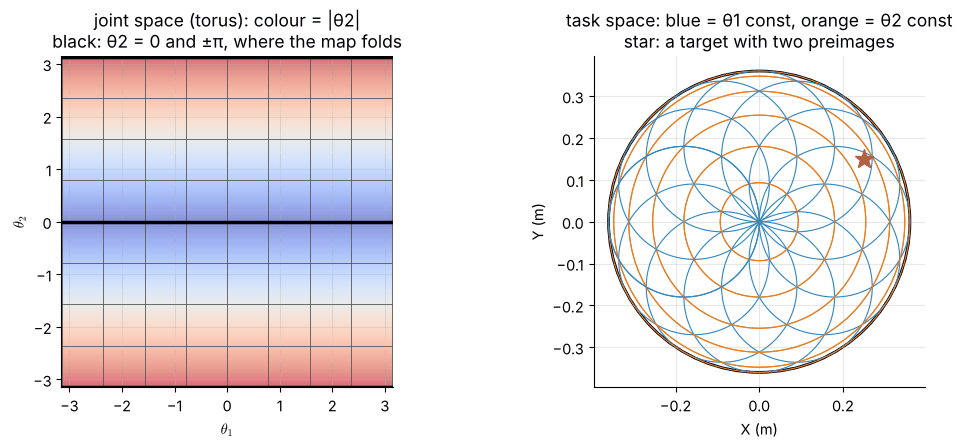

In [3]:
mujoco.mj_resetData(m2r, d2r); d2r.qpos[:] = 0; mujoco.mj_forward(m2r, d2r)
z0 = d2r.xanchor[0][2]
L1 = np.hypot(*(d2r.xanchor[1] - d2r.xanchor[0])[[0, 2]]); L2 = np.hypot(*(d2r.site("end").xpos - d2r.xanchor[1])[[0, 2]])
print(f"link lengths measured from the MuJoCo model: L1 = {L1:.4f} m, L2 = {L2:.4f} m")

def fk(q, L1=L1, L2=L2):
    q = np.asarray(q, float); t1, t12 = q[..., 0], q[..., 0] + q[..., 1]
    return np.stack([L1 * np.cos(t1) + L2 * np.cos(t12), L1 * np.sin(t1) + L2 * np.sin(t12)], axis=-1)

def mj_hand(q):                                              # MuJoCo tool point in the textbook plane (X down from the shoulder, Y = world x)
    d2r.qpos[:] = q; mujoco.mj_forward(m2r, d2r); p = d2r.site("end").xpos
    return np.array([z0 - p[2], p[0]])

def ik(p, L1=L1, L2=L2):
    """Both inverse solutions (elbow +, elbow -) or None if out of reach."""
    x, y = p; c2 = (x * x + y * y - L1 ** 2 - L2 ** 2) / (2 * L1 * L2)
    if abs(c2) > 1 + 1e-12: return None
    out = []
    for s in (+1, -1):
        q2 = s * np.arccos(np.clip(c2, -1, 1)); out.append(np.array([np.arctan2(y, x) - np.arctan2(L2 * np.sin(q2), L1 + L2 * np.cos(q2)), q2]))
    return out

rng = np.random.default_rng(4)
Q = rng.uniform(-np.pi, np.pi, size=(300, 2))
print("max |FK - MuJoCo| over 300 random configurations:", max(np.linalg.norm(fk(q) - mj_hand(q)) for q in Q))
target = np.array([0.25, 0.15]); sols = ik(target)
for s, q in zip("+-", sols):
    print(f"IK elbow {s}: q = {np.degrees(q).round(2)} deg -> MuJoCo hand {mj_hand(q).round(6)} (target {target})")
assert all(np.allclose(mj_hand(q), target, atol=1e-9) for q in sols)

fig, axs = plt.subplots(1, 2, figsize=(10.8, 4.6))
T1, T2 = np.meshgrid(np.linspace(-np.pi, np.pi, 300), np.linspace(-np.pi, np.pi, 300))
axs[0].pcolormesh(T1, T2, np.abs(T2), cmap="coolwarm", shading="auto", alpha=0.6)
for v in np.linspace(-np.pi, np.pi, 9): axs[0].axvline(v, color="#555", lw=0.6); axs[0].axhline(v, color="#555", lw=0.6)
axs[0].axhline(0, color="k", lw=2.5); axs[0].axhline(np.pi, color="k", lw=2.5); axs[0].axhline(-np.pi, color="k", lw=2.5)
axs[0].set_xlabel(r"$\theta_1$"); axs[0].set_ylabel(r"$\theta_2$"); axs[0].set_aspect("equal"); axs[0].set_title("joint space (torus): colour = |θ2|\nblack: θ2 = 0 and ±π, where the map folds")
t = np.linspace(-np.pi, np.pi, 400)
for a in np.linspace(-np.pi, np.pi, 13):
    axs[1].plot(*fk(np.column_stack([np.full_like(t, a), t])).T, "-", color="#2e86c1", lw=0.8)       # theta1 = const
    axs[1].plot(*fk(np.column_stack([t, np.full_like(t, a)])).T, "-", color="#e67e22", lw=0.8)       # theta2 = const
for r_ in (L1 + L2, abs(L1 - L2)): axs[1].add_patch(plt.Circle((0, 0), r_, fill=False, ec="k", lw=2))
axs[1].plot(*target, "*", color="#c0392b", ms=14); axs[1].set_aspect("equal"); axs[1].set_xlabel("X (m)"); axs[1].set_ylabel("Y (m)")
axs[1].set_title("task space: blue = θ1 const, orange = θ2 const\nstar: a target with two preimages")
plt.tight_layout(); plt.show()

## 3. The workspace of the 2R arm

> **Theorem.** The set of points the tip of a planar 2R arm with link lengths $L_1,L_2>0$ and unlimited joints can reach is the closed annulus
> $$\lvert L_1-L_2\rvert\ \le\ r\ \le\ L_1+L_2,\qquad r=\sqrt{X^2+Y^2}.$$

*Proof.* **(Necessity.)** The tip is $\mathbf p=L_1\hat{\mathbf u}_1+L_2\hat{\mathbf u}_2$ with unit vectors $\hat{\mathbf u}_i$. By the triangle inequality $\lVert\mathbf p\rVert\le L_1+L_2$ and
$\lVert\mathbf p\rVert\ge\lvert L_1-L_2\rvert$ (reverse triangle inequality). **(Sufficiency.)** Let $r$ satisfy both bounds. Put $\cos\theta_2 = (r^2-L_1^2-L_2^2)/(2L_1L_2)$; the bounds are *equivalent* to $\lvert\cos\theta_2\rvert\le1$ (for $r\le L_1+L_2$: $(r^2 - L_1^2 - L_2^2)\le 2L_1L_2$; for $r\ge\lvert L_1-L_2\rvert$: $\ge-2L_1L_2$), so a real $\theta_2$ exists. Then $\theta_1=\operatorname{atan2}(Y,X)-\operatorname{atan2}(L_2\sin\theta_2,L_1+L_2\cos\theta_2)$ places the tip at $\mathbf p$. $\square$

For the Dynamixel 2R, $L_1=L_2$, so the inner radius is $0$ and the annulus is a **disc** of radius $0.36$ m. The model, however, has **joint limits** $\theta_1\in[-110^\circ,110^\circ]$, $\theta_2\in[-150^\circ,150^\circ]$, which remove part of the disc. The experiment samples the *simulator* — random joint values within the limits, each passed through `mj_forward` — and compares the cloud with the analytic bounds; the bottom panels use an arm with unequal links to show the hole.

20000 samples of the real 2R through mj_forward:  r in [0.0932, 0.3600] m;   analytic bounds [0.0000, 0.3600] m
fraction of the disc of radius 0.36 m covered:  without joint limits 100.0%,  with the model's limits 80.8%


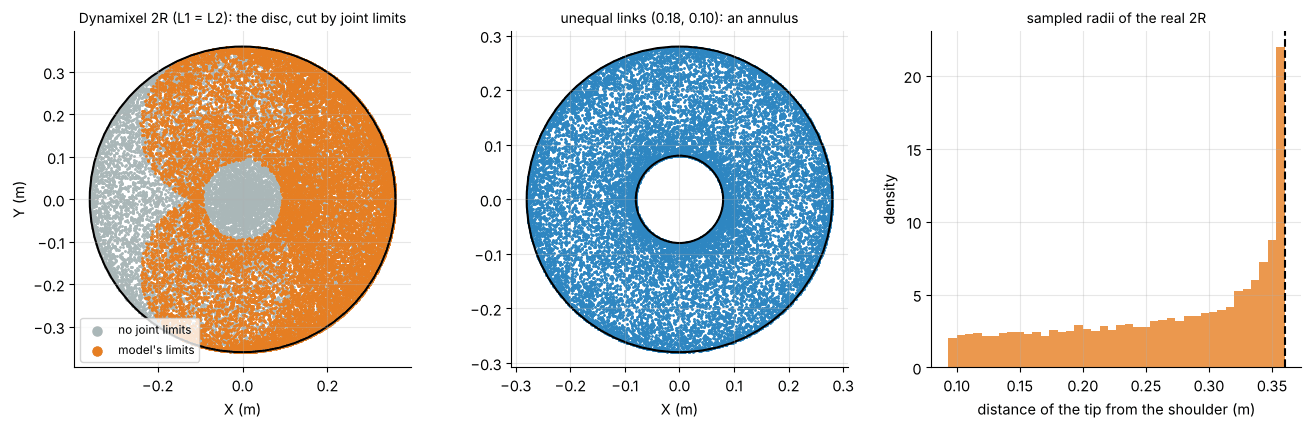

In [4]:
N = 20000
lo, hi = m2r.jnt_range[:, 0], m2r.jnt_range[:, 1]
Qs = rng.uniform(lo, hi, size=(N, 2)); tips = np.empty((N, 2))
for i, q in enumerate(Qs):
    d2r.qpos[:] = q; mujoco.mj_forward(m2r, d2r); p = d2r.site("end").xpos; tips[i] = (z0 - p[2], p[0])
r_s = np.hypot(*tips.T)
print(f"{N} samples of the real 2R through mj_forward:  r in [{r_s.min():.4f}, {r_s.max():.4f}] m;   analytic bounds [{abs(L1 - L2):.4f}, {L1 + L2:.4f}] m")
assert r_s.max() <= L1 + L2 + 1e-9 and r_s.min() >= abs(L1 - L2) - 1e-9

# fraction of the analytic disc actually covered (polar cells) with the model's joint limits vs without
def coverage(points, rmax, inner=0.0, nr=30, nphi=72):
    ph = np.arctan2(points[:, 1], points[:, 0]); rr = np.hypot(*points.T)
    ir = np.minimum((rr / rmax * nr).astype(int), nr - 1); ip = ((ph + np.pi) / (2 * np.pi) * nphi).astype(int) % nphi
    occ = np.zeros((nr, nphi), bool); occ[ir, ip] = True
    area = (np.arange(nr) + 0.5)[:, None] * np.ones(nphi)                       # cell area proportional to radius
    ring = (np.arange(nr) + 0.5) / nr * rmax >= inner
    return (area * occ * ring[:, None]).sum() / (area * ring[:, None]).sum()
free = fk(rng.uniform(-np.pi, np.pi, size=(N, 2)))
print(f"fraction of the disc of radius {L1 + L2:.2f} m covered:  without joint limits {coverage(free, L1 + L2):.1%},  with the model's limits {coverage(tips, L1 + L2):.1%}")

fig, axs = plt.subplots(1, 3, figsize=(13.4, 4.4))
axs[0].scatter(*free.T, s=1.2, color="#aab7b8", label="no joint limits"); axs[0].scatter(*tips.T, s=1.2, color="#e67e22", label="model's limits")
axs[0].add_patch(plt.Circle((0, 0), L1 + L2, fill=False, ec="k", lw=1.5)); axs[0].set_aspect("equal"); axs[0].legend(markerscale=6, fontsize=8.5, loc="lower left")
axs[0].set_title("Dynamixel 2R (L1 = L2): the disc, cut by joint limits", fontsize=10); axs[0].set_xlabel("X (m)"); axs[0].set_ylabel("Y (m)")
pts_u = fk(rng.uniform(-np.pi, np.pi, size=(N, 2)), 0.18, 0.10); axs[1].scatter(*pts_u.T, s=1.2, color="#2e86c1")
for r_ in (0.28, 0.08): axs[1].add_patch(plt.Circle((0, 0), r_, fill=False, ec="k", lw=1.5))
axs[1].set_aspect("equal"); axs[1].set_title("unequal links (0.18, 0.10): an annulus", fontsize=10); axs[1].set_xlabel("X (m)")
axs[2].hist(r_s, bins=40, color="#e67e22", alpha=0.8, density=True); axs[2].set_xlabel("distance of the tip from the shoulder (m)"); axs[2].set_ylabel("density")
axs[2].set_title("sampled radii of the real 2R", fontsize=10); axs[2].axvline(L1 + L2, color="k", lw=1.5, ls="--")
plt.tight_layout(); plt.show()

The sampled cloud lies inside the analytic disc, and sampling shows what the joint limits do: with $\theta_1$ restricted to $\pm110^\circ$ from the downward vertical the arm cannot swing far behind its shoulder, so a wedge of the disc is lost, and with $\lvert\theta_2\rvert\le150^\circ$ the elbow cannot fold completely, which opens a small hole of radius $2L\cos75^\circ=0.093$ m in the middle
(together about a fifth of the area, see the printed fraction). **Workspace analysis therefore needs the limits, not just the link lengths.** With unequal links (middle panel) the inner boundary $\lvert L_1-L_2\rvert$ is a real hole.

## 4. Sampling the workspace of a real arm

A 6-joint arm's workspace in $\mathbb R^3$ has no simple formula, but the same recipe — random joint values within limits, forward kinematics, collect the tool positions — estimates it. The UR5e is sampled below. Two questions arise: **how far out can it reach**, and **how many samples are enough**? For the first, there is a rigorous bound: the shoulder-to-flange distance is at most the sum of the rigid link vectors between consecutive joint anchors (triangle inequality again).
For the second, we count occupied voxels (5 cm cubes) as a function of the number of samples; the estimate of the workspace *volume* converges from below because random samples rarely hit the boundary.

UR5e: 20000 samples; largest shoulder-to-flange distance sampled = 1.0975 m; rigorous bound (sum of link vectors) = 1.1637 m (94.3% of the bound)
      tool heights z in [-0.79, 1.12] m; horizontal radius up to 0.964 m
occupied 5 cm voxels vs samples: [(250, 248), (500, 490), (1000, 960), (2000, 1852), (5000, 4225), (10000, 7361), (20000, 11941)]
estimated reachable volume from the last count: 1.49 m^3 (a lower estimate)


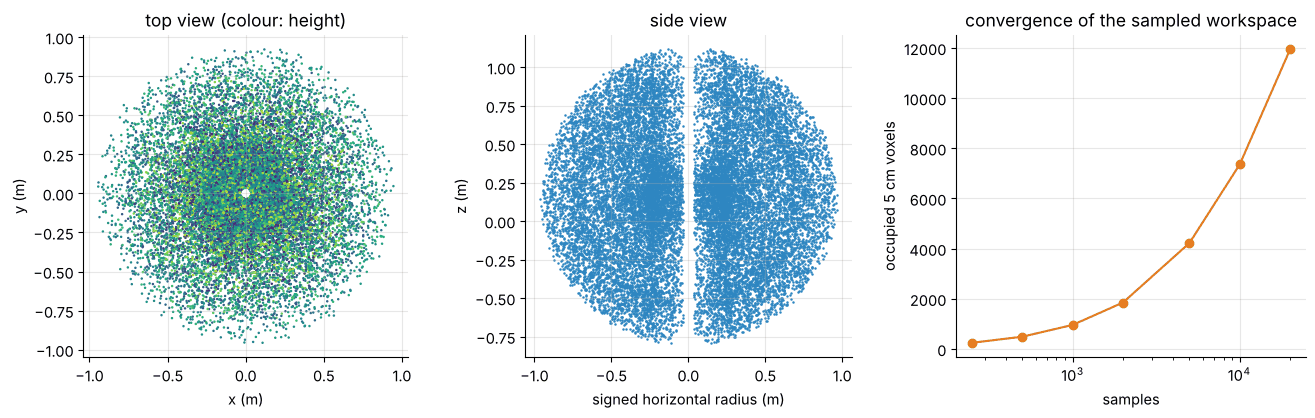

In [5]:
mU, dU = robots.load_robot("ur5e", scene="bare")
site = "attachment_site"
Nu = 20000
ranges = np.where(mU.jnt_limited[:, None], mU.jnt_range, [-np.pi, np.pi])
Qu = rng.uniform(ranges[:, 0], ranges[:, 1], size=(Nu, mU.nv)); P = np.empty((Nu, 3))
for i, q in enumerate(Qu):
    dU.qpos[:] = q; mujoco.mj_forward(mU, dU); P[i] = dU.site(site).xpos
dU.qpos[:] = mU.key_qpos[0]; mujoco.mj_forward(mU, dU)
rows = jc.joint_table(mU, dU); shoulder = rows[1]["anchor"]                                  # shoulder-lift joint anchor
chain_pts = [r["anchor"] for r in rows[1:]] + [dU.site(site).xpos]
bound = sum(np.linalg.norm(b - a) for a, b in zip(chain_pts[:-1], chain_pts[1:]))
dist = np.linalg.norm(P - shoulder, axis=1)
print(f"UR5e: {Nu} samples; largest shoulder-to-flange distance sampled = {dist.max():.4f} m; rigorous bound (sum of link vectors) = {bound:.4f} m ({dist.max() / bound:.1%} of the bound)")
assert dist.max() <= bound + 1e-9
print(f"      tool heights z in [{P[:, 2].min():.2f}, {P[:, 2].max():.2f}] m; horizontal radius up to {np.hypot(P[:, 0], P[:, 1]).max():.3f} m")

vox = 0.05; counts = []
for n_ in [250, 500, 1000, 2000, 5000, 10000, 20000]:
    counts.append((n_, len({tuple(v) for v in np.floor(P[:n_] / vox).astype(int)})))
print("occupied 5 cm voxels vs samples:", counts); print(f"estimated reachable volume from the last count: {counts[-1][1] * vox ** 3:.2f} m^3 (a lower estimate)")
fig, axs = plt.subplots(1, 3, figsize=(13.4, 4.3))
axs[0].scatter(P[:, 0], P[:, 1], s=0.6, c=P[:, 2], cmap="viridis"); axs[0].set_aspect("equal"); axs[0].set_xlabel("x (m)"); axs[0].set_ylabel("y (m)"); axs[0].set_title("top view (colour: height)")
axs[1].scatter(np.hypot(P[:, 0], P[:, 1]) * np.sign(P[:, 0]), P[:, 2], s=0.6, color="#2e86c1"); axs[1].set_aspect("equal"); axs[1].set_xlabel("signed horizontal radius (m)"); axs[1].set_ylabel("z (m)"); axs[1].set_title("side view")
axs[2].semilogx(*zip(*counts), "o-", color="#e67e22"); axs[2].set_xlabel("samples"); axs[2].set_ylabel("occupied 5 cm voxels"); axs[2].set_title("convergence of the sampled workspace")
plt.tight_layout(); plt.show()

The cloud is a thick spherical shell with a *hole around the shoulder* (the arm cannot reach points too close to its own shoulder), and it extends below the base plane because the model has no table. The farthest
reach stays below the geometric bound (94% of it) and approaches it only when the arm is almost stretched, which random sampling seldom produces. The voxel count is still rising steeply at 20 000
samples, so the volume estimate printed above (about 1.5 m³) is a *lower bound that has not converged*: six random joint values fill a six-dimensional joint space very unevenly, and the boundary of the workspace
is hit only rarely. Always plot such a convergence curve before quoting a sampled volume; for a precise boundary one uses optimisation (maximise the reach in each direction) rather than random sampling.

## 5. Reachable and dexterous workspace

Craig distinguishes two sets. The **reachable workspace** is the set of points the tool origin can reach with *at least one* orientation. The **dexterous workspace** is the set of points it can reach with *every* orientation
(of the types the task needs). The dexterous workspace is contained in the reachable one and is often much smaller, or **empty**: a planar 2R arm has two DOF, so it cannot choose both the position and the orientation of its tool, and its dexterous workspace
for the planar pose is empty. A planar 3R arm has 3 DOF, enough for position and orientation, and we can compute both sets.

For link lengths $L_1,L_2,L_3$: the tool at $\mathbf p$ with orientation $\varphi$ requires the **wrist point** $\mathbf w=\mathbf p-L_3(\cos\varphi,\sin\varphi)$ to be reachable by the first two links, i.e. $\lvert L_1-L_2\rvert\le\lVert\mathbf w\rVert\le L_1+L_2$ (Section 3). The
reachable set is the union over $\varphi$, the dexterous set the intersection. For $L_1=L_2=1$ and $L_3=0.5$ the worst orientation points the last link along $\mathbf p$, so dexterity requires $\lVert\mathbf p\rVert+L_3\le L_1+L_2$: a **disc of radius 1.5**, whereas the reachable workspace is the disc of radius 2.5.

reachable points: 4158, dexterous points: 1496 of 6000
mismatch with the analytic discs (outside a 0.01 band at the boundary): reachable 0 , dexterous 0


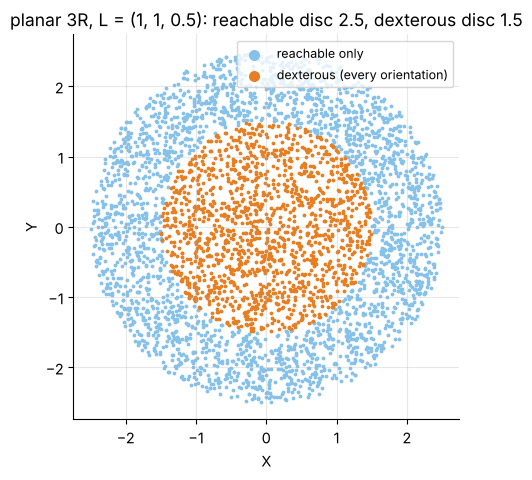

In [6]:
L = (1.0, 1.0, 0.5)
def wrist_ok(p, phi, L=L):
    w = p - L[2] * np.array([np.cos(phi), np.sin(phi)]); r = np.linalg.norm(w)
    return abs(L[0] - L[1]) <= r <= L[0] + L[1]
rng3 = np.random.default_rng(8)
pts = rng3.uniform(-2.7, 2.7, size=(6000, 2)); phis = np.linspace(-np.pi, np.pi, 720, endpoint=False)
ok = np.array([[wrist_ok(p, f) for f in phis] for p in pts])
reach = ok.any(axis=1); dext = ok.all(axis=1)
rp = np.linalg.norm(pts, axis=1)
band = np.abs(rp - 2.5) < 0.01; band2 = np.abs(rp - 1.5) < 0.01
print(f"reachable points: {reach.sum()}, dexterous points: {dext.sum()} of {len(pts)}")
print("mismatch with the analytic discs (outside a 0.01 band at the boundary): reachable", int(((reach != (rp <= 2.5)) & ~band).sum()), ", dexterous", int(((dext != (rp <= 1.5)) & ~band2).sum()))
assert ((reach != (rp <= 2.5)) & ~band).sum() == 0 and ((dext != (rp <= 1.5)) & ~band2).sum() == 0

fig, ax = plt.subplots(figsize=(5.4, 5.0))
ax.scatter(*pts[reach & ~dext].T, s=3, color="#85c1e9", label="reachable only"); ax.scatter(*pts[dext].T, s=3, color="#e67e22", label="dexterous (every orientation)")
ax.set_aspect("equal"); ax.legend(markerscale=4, fontsize=9, loc="upper right"); ax.set_title("planar 3R, L = (1, 1, 0.5): reachable disc 2.5, dexterous disc 1.5"); ax.set_xlabel("X"); ax.set_ylabel("Y")
plt.show()

## 6. Task space and redundancy

The robot's DOF $n$ and the task's dimension $m$ are independent numbers, and their comparison classifies the situation.

| Case | Meaning | Examples |
|:--|:--|:--|
| $n = m$ | just enough joints: finitely many IK solutions at regular configurations | 6R arm for a 6-D pose; 2R for a planar position |
| $n < m$ | too few: not every task pose is reachable (the *dexterous* workspace is empty for the full task) | 2R for position *and* orientation; a 5-DOF arm for a 6-D pose |
| $n > m$ | **redundant**: infinitely many IK solutions; the surplus $n-m$ is the dimension of the **self-motion** manifold along which the joints move while the tool stays put | 7R arm for a 6-D pose; 3R arm for a planar position (task $m=2$); 6R arm for a pointing task (position + one axis, $m=5$) |

Redundancy is relative to the task. The Jacobian $J(\mathbf q)$ (Chapter 5) maps joint velocities to tool velocity; its **null space** has dimension $n-\operatorname{rank}J$, and moving along it changes the arm's shape without moving the tool. The experiment uses the iiwa 14, a 7-joint arm
with a 6-D task: at a generic configuration $J$ is $6\times7$ with rank 6, so the null space is one-dimensional. We follow the null space (with a small Newton correction to remove second-order drift), keep the hand pose fixed, and watch the **elbow** swing.

Jacobian of the iiwa 14 (6 x 7): singular values [1.783 1.653 1.118 0.311 0.192 0.146] -> rank 6 -> null space dimension 1


after the self-motion: joint change [45.7  6.6 29.9  0.  66.9  4.8 72.3] deg (max 72.3°)
hand drift: position 0.0000 mm, orientation 0.00000°;   elbow (link 4) moved by 32.0 cm


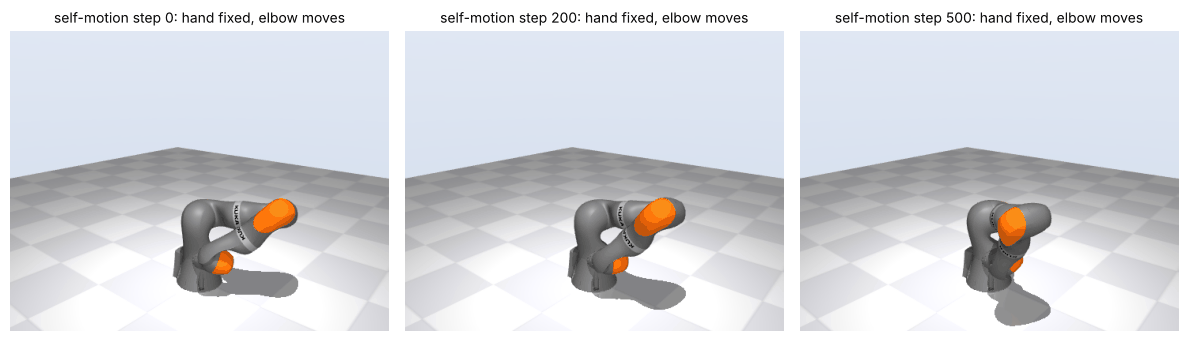

In [7]:
mI, dI = robots.load_robot("iiwa14", scene="light")
qI = mI.key_qpos[0].copy(); qI[[1, 3, 5]] += [0.6, -1.0, 0.7]; qI[[0, 2, 4]] += [0.3, -0.4, 0.5]          # a generic non-singular pose
hand, elbow = mujoco.mj_name2id(mI, mujoco.mjtObj.mjOBJ_BODY, "link7"), mujoco.mj_name2id(mI, mujoco.mjtObj.mjOBJ_BODY, "link4")

def pose_and_jac(q):
    dI.qpos[:] = q; mujoco.mj_forward(mI, dI)
    jp, jr = np.zeros((3, mI.nv)), np.zeros((3, mI.nv)); mujoco.mj_jacBody(mI, dI, jp, jr, hand)
    return dI.xpos[hand].copy(), dI.xmat[hand].reshape(3, 3).copy(), np.vstack([jp, jr])

def rot_err(Rt, R):                                     # small rotation vector taking R to Rt (world frame)
    return 0.5 * sum(np.cross(R[:, i], Rt[:, i]) for i in range(3))

p0, R0, J0 = pose_and_jac(qI)
sv = np.linalg.svd(J0, compute_uv=False)
print("Jacobian of the iiwa 14 (6 x 7): singular values", sv.round(3), "-> rank", int((sv > 1e-8).sum()), "-> null space dimension", mI.nv - int((sv > 1e-8).sum()))
q, qs, elbows = qI.copy(), [qI.copy()], [dI.xpos[elbow].copy()]
for step in range(500):
    p, R, J = pose_and_jac(q)
    n = np.linalg.svd(J)[2][-1]
    if step == 0: n0 = n.copy()
    n = n if n @ n0 >= 0 else -n; n0 = n.copy()                       # keep a consistent sign
    q = q + 0.004 * n
    p, R, J = pose_and_jac(q)
    q = q + np.linalg.pinv(J) @ np.concatenate([p0 - p, rot_err(R0, R)])      # Newton correction back onto the fixed-pose set
    if step % 100 == 99:
        qs.append(q.copy()); pose_and_jac(q); elbows.append(dI.xpos[elbow].copy())
p, R, _ = pose_and_jac(q)
print(f"after the self-motion: joint change {np.degrees(np.abs(q - qI)).round(1)} deg (max {np.degrees(np.abs(q - qI)).max():.1f}°)")
print(f"hand drift: position {np.linalg.norm(p - p0) * 1000:.4f} mm, orientation {np.degrees(np.linalg.norm(rot_err(R0, R))):.5f}°;   elbow (link 4) moved by {np.linalg.norm(elbows[-1] - elbows[0]) * 100:.1f} cm")
assert np.linalg.norm(p - p0) < 1e-4 and np.linalg.norm(rot_err(R0, R)) < 1e-3 and np.linalg.norm(elbows[-1] - elbows[0]) > 0.05

imgs, titles = [], []
for k in (0, 2, 5):
    dI.qpos[:] = qs[k]; mujoco.mj_forward(mI, dI)
    imgs.append(mju.render(mI, dI, camera=dict(azimuth=130, elevation=-15, distance=1.8, lookat=(0, 0, 0.55)), width=480, height=380))
    titles.append(f"self-motion step {k * 100}: hand fixed, elbow moves")
filmstrip(imgs, titles)

Six of the seven joint angles changed, by up to $72^\circ$, the elbow moved by $32$ cm, and the hand stayed put to better than a hundredth of a millimetre: that is *self-motion*, the practical meaning of redundancy. (Joint 4, the elbow joint, did not change: the shoulder–wrist distance is fixed by the hand pose, so the elbow can only *swing around the shoulder–wrist line*.)
A human arm has 7 DOF for a 6-D hand pose; the same freedom lets you lift your elbow without moving your hand. It can be used to avoid obstacles, stay away from joint limits or singularities — the subject of Chapter 5.
For a non-redundant arm the same computation gives a trivial null space, which the cell below confirms for the UR5e.

In [8]:
def jac_rank(m, d, body):
    jp, jr = np.zeros((3, m.nv)), np.zeros((3, m.nv)); mujoco.mj_jacBody(m, d, jp, jr, mujoco.mj_name2id(m, mujoco.mjtObj.mjOBJ_BODY, body))
    return np.linalg.matrix_rank(np.vstack([jp, jr]), tol=1e-8)
mU2, dU2 = robots.load_robot("ur5e", scene="bare"); dU2.qpos[:] = random_q = rng.uniform(-1.0, 1.0, 6); mujoco.mj_forward(mU2, dU2)
mP2, dP2 = robots.load_robot("panda", scene="bare"); dP2.qpos[:7] = rng.uniform(-1.0, 1.0, 7); dP2.qpos[3] = -1.5; mujoco.mj_forward(mP2, dP2)
lines = ["| robot | joints $n$ | task dimension $m$ | rank of $J$ | redundancy / null space $n - \\mathrm{rank}\\,J$ |", "|:--|:-:|:-:|:-:|:-:|"]
for name, (m_, d_, body, n_) in {"UR5e": (mU2, dU2, "wrist_3_link", 6), "Panda (arm only)": (mP2, dP2, "link7", 7), "iiwa 14": (mI, dI, "link7", 7)}.items():
    jr_ = jac_rank(m_, d_, body); lines.append(f"| {name} | {n_} | 6 | {jr_} | {n_ - jr_} |")
display(Markdown("\n".join(lines)))

| robot | joints $n$ | task dimension $m$ | rank of $J$ | redundancy / null space $n - \mathrm{rank}\,J$ |
|:--|:-:|:-:|:-:|:-:|
| UR5e | 6 | 6 | 6 | 0 |
| Panda (arm only) | 7 | 6 | 6 | 1 |
| iiwa 14 | 7 | 6 | 6 | 1 |

## 7. Worked examples

**Example 1.5.1 (two spaces).** The Panda's gripper actuator has length $\ell=\tfrac12(q_8+q_9)$. If $q_8=q_9=0.02$ m, what is the actuator reading, and if the controller commands $\ell=0.03$ m what are the finger positions?
*Solution.* $\ell=0.02$ m; commanding $0.03$ m gives $q_8=q_9=0.03$ m (they are constrained equal). (Section 1 verifies the matrix $[\tfrac12\ \tfrac12]$.)

**Example 1.5.2 (FK of the 2R).** For $L_1=L_2=0.18$ m and $(\theta_1,\theta_2)=(30^\circ,60^\circ)$ compute the tool position and compare with MuJoCo. *Solution.* $X=0.18\cos30^\circ+0.18\cos90^\circ=0.1559$ m, $Y=0.18\sin30^\circ+0.18\sin90^\circ=0.27$ m.

**Example 1.5.3 (IK, two solutions).** Find both joint solutions for the target $(0.25, 0.15)$ m. *Solution.* $\cos\theta_2=(0.25^2+0.15^2-2\cdot0.18^2)/(2\cdot0.18^2) = 0.3117\Rightarrow\theta_2=\pm71.84^\circ$; the matching $\theta_1$ are $-4.95^\circ$ (for $+71.84^\circ$) and $66.88^\circ$ (for $-71.84^\circ$). The code checks both in MuJoCo.

**Example 1.5.4 (the annulus).** A 2R arm has $L_1=0.5$ m and $L_2=0.2$ m. Which of the points $(0.4, 0.1)$, $(0.1, 0.1)$, $(0.8, 0)$ are reachable? *Solution.* The annulus is $0.3\le r\le0.7$; the radii are $0.412$ (yes), $0.141$ (no, inside the hole), $0.8$ (no, too far).

**Example 1.5.5 (dexterous workspace).** What are the reachable and dexterous radii of a planar 3R arm with $L=(1,1,0.5)$? *Solution.* Reachable $r\le L_1+L_2+L_3=2.5$; dexterous $r\le L_1+L_2-L_3=1.5$ (Section 5).

**Example 1.5.6 (redundancy).** A 7R arm performs a 3-D position task ($m=3$). What is its redundancy? *Solution.* $n-m=4$; for a full pose ($m=6$) it is 1.

**Example 1.5.7 (UR5e reach).** Compare the largest sampled shoulder-to-flange distance of the UR5e with the geometric bound. *Solution.* $1.098$ m sampled against a bound of $1.164$ m: $94.3\%$ (Section 4).

In [9]:
# 1.5.1
print("1.5.1  actuator reading for q8 = q9 = 0.02:", Tp[7, 7:] @ [0.02, 0.02])
assert np.isclose(Tp[7, 7:] @ [0.02, 0.02], 0.02)
# 1.5.2
q = np.radians([30, 60]); print("1.5.2  FK:", fk(q).round(4), "| MuJoCo:", mj_hand(q).round(4)); assert np.allclose(fk(q), [0.18 * np.cos(np.radians(30)), 0.18 * np.sin(np.radians(30)) + 0.18], atol=1e-4) and np.allclose(fk(q), mj_hand(q))
# 1.5.3
c2 = (0.25 ** 2 + 0.15 ** 2 - 2 * 0.18 ** 2) / (2 * 0.18 ** 2); s = ik(np.array([0.25, 0.15]))
print("1.5.3  cos(theta2) =", round(c2, 4), "| solutions (deg):", [np.degrees(x).round(2) for x in s]); assert np.isclose(abs(np.degrees(s[0][1])), 71.84, atol=0.01)
# 1.5.4
print("1.5.4  radii:", [round(float(np.hypot(*p)), 3) for p in [(0.4, 0.1), (0.1, 0.1), (0.8, 0.0)]], "annulus [0.3, 0.7]")
assert [0.3 <= np.hypot(*p) <= 0.7 for p in [(0.4, 0.1), (0.1, 0.1), (0.8, 0.0)]] == [True, False, False]
# 1.5.5, 1.5.6
print("1.5.5  reachable", sum(L), "dexterous", L[0] + L[1] - L[2], "| 1.5.6  redundancy:", 7 - 3, 7 - 6)
# 1.5.7
print(f"1.5.7  UR5e: sampled max distance {dist.max():.4f} m, bound {bound:.4f} m, ratio {dist.max() / bound:.3f}")

1.5.1  actuator reading for q8 = q9 = 0.02: 0.020000000000020002
1.5.2  FK: [0.1559 0.27  ] | MuJoCo: [0.1559 0.27  ]
1.5.3  cos(theta2) = 0.3117 | solutions (deg): [array([-4.95, 71.84]), array([ 66.88, -71.84])]
1.5.4  radii: [0.412, 0.141, 0.8] annulus [0.3, 0.7]
1.5.5  reachable 2.5 dexterous 1.5 | 1.5.6  redundancy: 4 1
1.5.7  UR5e: sampled max distance 1.0975 m, bound 1.1637 m, ratio 0.943


## 8. Summary

| Idea | Result |
|:--|:--|
| Spaces | actuator, joint, task space and workspace; maps: transmission, FK (unique), IK (0, finitely many or infinitely many) |
| Transmission | not always the identity: differential wrists, coupled fingers; map actuators to joints by the model's table (the 2R's `ctrl[0]` drives the elbow) |
| 2R workspace | annulus $\lvert L_1-L_2\rvert\le r\le L_1+L_2$; FK folds the torus onto it along $\theta_2\in\{0,\pi\}$; two IK solutions inside |
| Joint limits | cut the workspace (the real 2R covers only part of its disc) |
| Sampling | random joint values $\to$ `mj_forward` gives the workspace of any arm; converges slowly from inside (boundary under-sampled), so plot the convergence and compare with a rigorous bound |
| Reachable vs dexterous | some orientation vs every orientation; dexterous $\subset$ reachable; planar 3R, $L=(1,1,0.5)$: discs of radius 2.5 and 1.5 |
| Redundancy | $n-m$ with $m$ the task dimension; null space of $J$ = self-motion; iiwa 14: 7 joints, 6-D task, 1-D self-motion |

### Common mistakes

* Treating the **link length sum** as the workspace: joint limits, self-collision and the inner hole $\lvert L_1-L_2\rvert$ all matter.
* Assuming **ctrl[i] moves joint i**: use the actuator–joint table.
* Calling an arm "6-DOF therefore it reaches any pose": reachable and dexterous workspace differ, and singularities remove directions.
* Thinking IK has **one** answer; FK does.
* Calling redundancy a property of the robot alone: it is $n-m$ and depends on the task.

## Exercises

**1.5.1** A planar 2R arm has $L_1=0.5$, $L_2=0.3$. State its reachable workspace. Is the point $(0.15, 0.1)$ reachable? Is $(0.6, 0.45)$?

<details><summary>Answer</summary>

Annulus $0.2\le r\le0.8$. $(0.15,0.1)$ has $r=0.180<0.2$: no (inside the hole). $(0.6,0.45)$ has $r=0.75$: yes.
</details>

**1.5.2** Show that for the planar 2R, $\det J=L_1L_2\sin\theta_2$ and explain the fold of Section 2.

<details><summary>Answer</summary>

$J=\begin{bmatrix}-L_1s_1-L_2s_{12}&-L_2s_{12}\\ L_1c_1+L_2c_{12}&L_2c_{12}\end{bmatrix}$, so $\det J = -L_1L_2 s_1c_{12}-L_2^2s_{12}c_{12}+L_1L_2c_1s_{12}+L_2^2s_{12}c_{12} = L_1L_2(c_1s_{12}-s_1c_{12})=L_1L_2\sin\theta_2$. It vanishes at $\theta_2=0,\pi$, where two preimages merge: the fold.
</details>

**1.5.3** The planar 3R with $L=(1,1,0.5)$: is the point $(2.0, 0)$ reachable with orientation $\varphi=90^\circ$? Dexterous?

<details><summary>Answer</summary>

With $\varphi=90^\circ$ the wrist point is $(2,-0.5)$, $r=2.06\le2$? No: $2.06>2$, so **not reachable with that orientation**; it is reachable with other orientations (e.g. $\varphi=0$: wrist point $(1.5,0)$). It is therefore reachable but not dexterous, consistent with $r=2>1.5$.
</details>

**1.5.4** A 5-joint arm (5R) is used for a 6-D pose task. Can it reach an arbitrary pose in its workspace? What is its dexterous workspace?

<details><summary>Answer</summary>

No: $n=5<m=6$, so poses form a 5-dimensional subset of the 6-D task space; the dexterous workspace (all orientations at a point) is empty.
</details>

**1.5.5** (*MuJoCo*) Sample 5000 random configurations of the Sawyer and report the largest distance of the last link from the first joint anchor, and its bound by the triangle inequality.

<details><summary>Answer</summary>

Computed in the check cell below: the sampled maximum is below the bound (sum of link vectors between consecutive anchors).
</details>

**1.5.6** (*programming*) For the real 2R sampled in Section 3, estimate the fraction of the annulus covered when only $\theta_2\in[-150^\circ,150^\circ]$ is limited (θ1 free).

<details><summary>Answer</summary>

The radius $r$ depends only on $\theta_2$, and with $\theta_1$ free every direction is covered, so only the central hole $r<2L\cos75^\circ=0.093$ m is missing; its area fraction is $(0.093/0.36)^2=6.7\%$, so the coverage is about $93$–$94\%$ (the check prints the polar-cell estimate, $94.4\%$).
</details>

In [10]:
# --- verification of the exercise answers ---
print("1.5.1  radii:", round(float(np.hypot(0.15, 0.1)), 3), round(float(np.hypot(0.6, 0.45)), 3), "annulus [0.2, 0.8]")
t1, t2 = 0.7, 1.1; J = np.array([[-0.5 * np.sin(t1) - 0.3 * np.sin(t1 + t2), -0.3 * np.sin(t1 + t2)], [0.5 * np.cos(t1) + 0.3 * np.cos(t1 + t2), 0.3 * np.cos(t1 + t2)]])
print("1.5.2  det J =", round(np.linalg.det(J), 6), " L1 L2 sin(theta2) =", round(0.5 * 0.3 * np.sin(t2), 6)); assert np.isclose(np.linalg.det(J), 0.5 * 0.3 * np.sin(t2))
print("1.5.3  wrist point for phi = 90 deg:", [2.0, -0.5], "r =", round(float(np.hypot(2.0, -0.5)), 3), "| reachable with phi = 90°:", wrist_ok(np.array([2.0, 0.0]), np.pi / 2), "| with phi = 0:", wrist_ok(np.array([2.0, 0.0]), 0.0))
mS, dS = robots.load_robot("sawyer", scene="bare"); mujoco.mj_forward(mS, dS)
rowsS = jc.chain_joints(mS, dS, "right_l6"); base_pt = rowsS[0]["anchor"]
boundS = sum(np.linalg.norm(b["anchor"] - a["anchor"]) for a, b in zip(rowsS[:-1], rowsS[1:])) + np.linalg.norm(dS.body("right_l6").xpos - rowsS[-1]["anchor"])
far = 0.0
for _ in range(5000):
    q = mS.qpos0.copy()
    for j in range(mS.njnt):
        if mS.jnt_type[j] == 3 and mS.jnt_limited[j]: q[mS.jnt_qposadr[j]] = rng.uniform(*mS.jnt_range[j])
    dS.qpos[:] = q; mujoco.mj_forward(mS, dS); far = max(far, np.linalg.norm(dS.body("right_l6").xpos - base_pt))
print(f"1.5.5  Sawyer: sampled max distance {far:.3f} m <= bound {boundS:.3f} m:", far <= boundS + 1e-9); assert far <= boundS + 1e-9
cov = coverage(fk(np.column_stack([rng.uniform(-np.pi, np.pi, N), rng.uniform(-np.radians(150), np.radians(150), N)])), L1 + L2)
print(f"1.5.6  coverage of the disc with theta1 free and |theta2| <= 150°: {cov:.1%}")

1.5.1  radii: 0.18 0.75 annulus [0.2, 0.8]
1.5.2  det J = 0.133681  L1 L2 sin(theta2) = 0.133681
1.5.3  wrist point for phi = 90 deg: [2.0, -0.5] r = 2.062 | reachable with phi = 90°: False | with phi = 0: True


1.5.5  Sawyer: sampled max distance 1.242 m <= bound 1.325 m: True
1.5.6  coverage of the disc with theta1 free and |theta2| <= 150°: 94.4%


## Further reading and lectures

* Craig §3.6 (the three spaces) and §4.2 (workspace; existence of solutions); Lynch & Park §2.5 (task space and workspace); Siciliano et al. §2.9 (kinematic redundancy); Spong et al., Ch. 1 and Ch. 3.
* Video: [Modern Robotics — 2.5 Task space and workspace](https://www.youtube.com/watch?v=hTuW51CpUg4); [Prof. G. C. Nandi — Lecture 3 — Simple concepts of forward and inverse kinematics](https://www.youtube.com/watch?v=2ww-3c08BIs); [Prof. G. C. Nandi — Lecture 2 — A simple two-link manipulator](https://www.youtube.com/watch?v=4eAlCjFMq2Q).
* This is the last notebook of Chapter 1. Chapter 2 (spatial descriptions and transformations) develops the frames used to describe the task space; Chapter 3 builds the forward-kinematics map of arbitrary arms.

---

[← 1.4 Configuration Space](1.4-configuration-space.ipynb) &nbsp;·&nbsp; [Chapter contents](README.md)